# Comparison of Cox models with two factors

With two factors there are five possible Cox models: no variables, each factor alone, the two factors, and the two factors with their interaction. Nested models are compared with the log-likelihood ratio test, and all of them can be compared with the AIC.

The data are the survival times, in months, of 36 patients with a malignant tumour in the kidney (hypernephroma). The factors are whether the kidney was removed (`nephrectomy`, 0 = no, 1 = yes) and the age group (`age`, 1 = under 60, 2 = 60 to 70, 3 = over 70).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import chi2
from lifelines import CoxPHFitter, KaplanMeierFitter

In [2]:
# Colors shared by all the plots
point_color = '#c1121f'
line_color  = '#1f4e79'
opt_color   = '#E69F00'
CLASS_COLORS = ['#1f4e79', '#E69F00', '#009E73']

## The data

In [3]:
DatOriginal = pd.read_csv("data/hypernephroma_treatment.dat", sep=r"\s+")

In [4]:
DatOriginal.head()

,nephrectomy,age,time,status
0,0,1,9,1
1,0,1,6,1
2,0,1,21,1
3,0,2,15,1
4,0,2,8,1


In [5]:
DatOriginal.groupby(['nephrectomy', 'age']).agg(patients=('time', 'size'), deaths=('status', 'sum')).unstack('age')

patients       deaths      
age                1  2  3      1  2  3
nephrectomy                            
0                  3  3  1      3  3  1
1                 16  9  4     14  7  4

Kaplan-Meier estimator for the levels of each factor. The patients without nephrectomy and the oldest ones seem to have a shorter survival. There are few patients in some combinations of the two factors (see the table above).

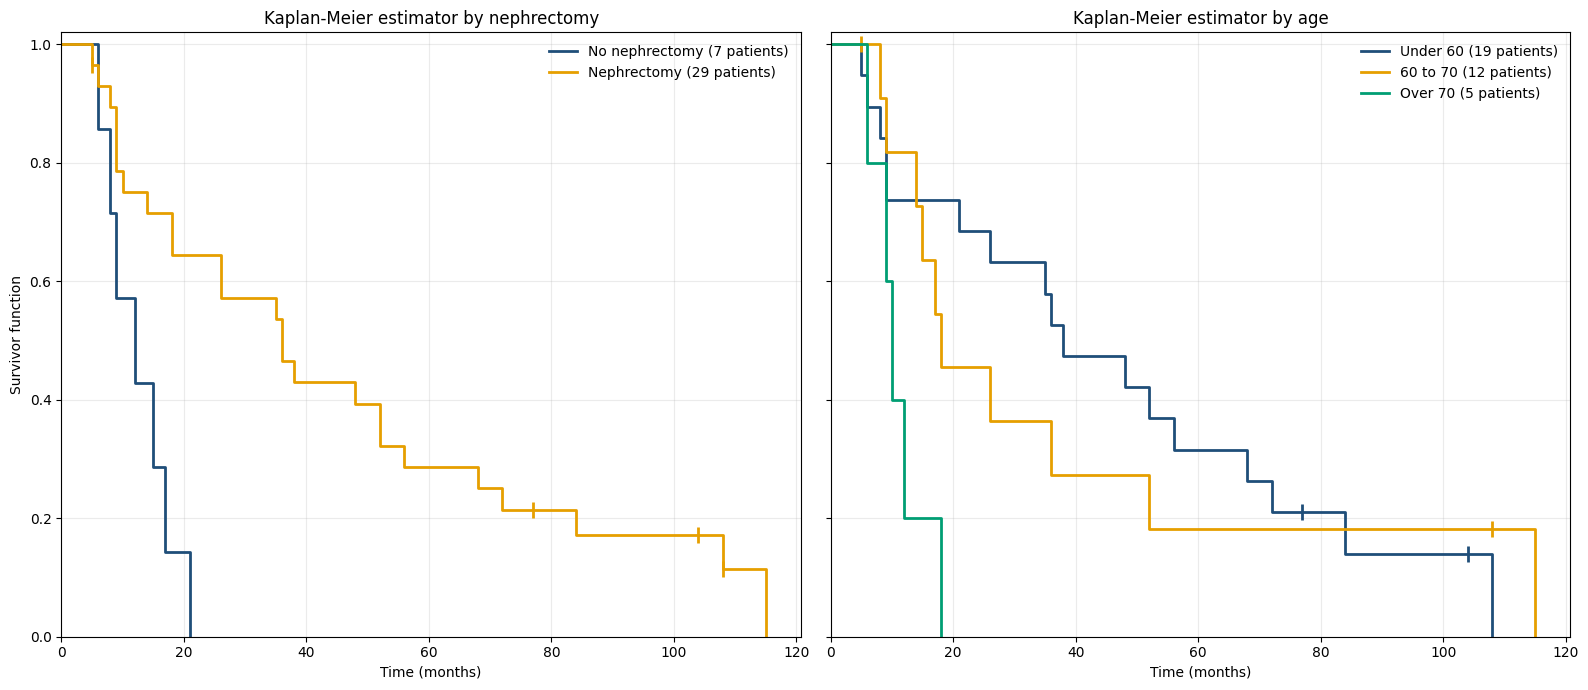

In [6]:
labels = {'nephrectomy': {0: 'No nephrectomy', 1: 'Nephrectomy'},
          'age': {1: 'Under 60', 2: '60 to 70', 3: 'Over 70'}}

fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharey=True)
for ax, factor in zip(axes, ['nephrectomy', 'age']):
    for (level, DatGroup), color in zip(DatOriginal.groupby(factor), CLASS_COLORS):
        kmf = KaplanMeierFitter().fit(DatGroup['time'], event_observed=DatGroup['status'])
        surv = kmf.survival_function_.iloc[:, 0]
        censored = kmf.event_table.index[kmf.event_table['censored'] > 0]
        ax.step(surv.index, surv, where='post', color=color, lw=2, label=f'{labels[factor][level]} ({len(DatGroup)} patients)')
        ax.plot(censored, surv.loc[censored], '|', color=color, markersize=11, markeredgewidth=2)
    ax.set_xlabel('Time (months)')
    ax.set_xlim(0, None)
    ax.set_ylim(0, 1.02)
    ax.set_title(f'Kaplan-Meier estimator by {factor}')
    ax.legend(loc='upper right', frameon=False)
    ax.grid(True, alpha=0.25)
axes[0].set_ylabel('Survivor function')
plt.tight_layout()

## Comparing the models

Function that calculates the test statistic and $P$-value to compare two nested models based on the log-likelihood ratio test.

In [7]:
def LoglikeRatioTest(minus2loglike_model1, minus2loglike_model2, df_model1, df_model2):
    # model1 must be nested in model2, i.e. model2 has more variables than model1
    test_statistic = minus2loglike_model1 - minus2loglike_model2
    p_value = chi2.sf(test_statistic, df_model2-df_model1)
    return test_statistic, p_value

The data only has two factors: age and nephrectomy.

We can create a model for each possible combination of these factors, with and without their interaction, i.e., we can build 5 models.

In [8]:
formulas = [
    'C(age)', 'C(nephrectomy)', 'C(age)+C(nephrectomy)', 'C(age)+C(nephrectomy)+C(age)*C(nephrectomy)'
]

MinusTwoLogLike = []
Aic = []
DegreesFreedom = []

for i,f in enumerate(formulas):

    cph = CoxPHFitter()
    Model = cph.fit(DatOriginal, 'time', 'status', formula=f)

    if i==0:
        _ = -2*Model.log_likelihood_ + Model.log_likelihood_ratio_test().test_statistic
        MinusTwoLogLike.append(_)
        DegreesFreedom.append(0)
        Aic.append(_)

    MinusTwoLogLike.append(-2*Model.log_likelihood_)
    DegreesFreedom.append(len(Model.summary))
    Aic.append(Model.AIC_partial_)

formulas.insert(0, 'None')

ModelSummary = pd.DataFrame({'formula': formulas, '-2log-L': MinusTwoLogLike, 'AIC': Aic, 'df': DegreesFreedom})

In [9]:
ModelSummary.round(3)

,formula,-2log-L,AIC,df
0,None,176.586,176.586,0
1,C(age),170.801,174.801,2
2,C(nephrectomy),169.022,171.022,1
3,C(age)+C(nephrectomy),164.223,170.223,3
4,C(age)+C(nephrectomy)+C(age)*C(nephrectomy),160.833,170.833,5


Is there an interaction between age and nephrectomy?

In [10]:
# Comparing model C(age)+C(nephrectomy)+C(age)*C(nephrectomy) against model C(age)+C(nephectomy), i.e. omitting C(age)*C(nephrectomy)
np.round(LoglikeRatioTest(
    ModelSummary.loc[3]['-2log-L'],
    ModelSummary.loc[4]['-2log-L'],
    ModelSummary.loc[3]['df'],
    ModelSummary.loc[4]['df']
),3)

#We do not reject the null hypothesis. So, there is no interaction between age and nephrectomy

array([3.39 , 0.184])

Is age needed in the model?

In [11]:
# Comparing model C(age)+C(nephrectomy) against model C(nephectomy), i.e. omitting C(age)
np.round(LoglikeRatioTest(
    ModelSummary.loc[2]['-2log-L'],
    ModelSummary.loc[3]['-2log-L'],
    ModelSummary.loc[2]['df'],
    ModelSummary.loc[3]['df']
),3)

#We reject the null hypothesis at the 10% level. So, we need age

array([4.799, 0.091])

Is nephrectomy needed in the model?

In [12]:
# Comparing model C(age)+C(nephrectomy) against model C(age), i.e. omitting C(nephrectomy)
np.round(LoglikeRatioTest(
    ModelSummary.loc[1]['-2log-L'],
    ModelSummary.loc[3]['-2log-L'],
    ModelSummary.loc[1]['df'],
    ModelSummary.loc[3]['df']
),3)

#We reject the null hypothesis. So, we need nephrectomy

array([6.577, 0.01 ])

We could have checked the model with the smallest AIC

In [13]:
ModelSummary.loc[ModelSummary['AIC'].argmin()]

formula    C(age)+C(nephrectomy)
-2log-L               164.223322
AIC                   170.223322
df                             3
Name: 3, dtype: object

The statistic $-2\log L$ always decreases when variables are added; the AIC adds twice the number of parameters, so it only decreases when the improvement is worth the extra parameters.

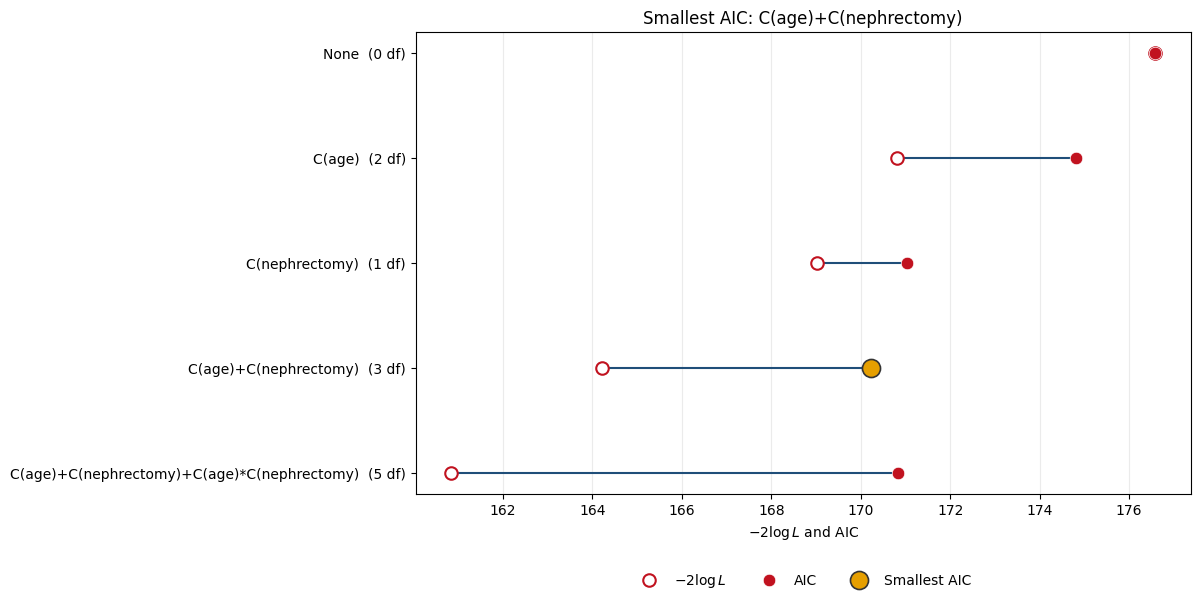

In [14]:
Best = ModelSummary['AIC'].argmin()
position = np.arange(len(ModelSummary))[::-1]

fig, ax = plt.subplots(figsize=(10, 6))
ax.hlines(position, ModelSummary['-2log-L'], ModelSummary['AIC'], color=line_color, lw=1.5)
ax.plot(ModelSummary['-2log-L'], position, 'o', markerfacecolor='white', markersize=9, markeredgecolor=point_color,
        markeredgewidth=1.5, label=r'$-2\log L$')
ax.plot(ModelSummary['AIC'], position, 'o', color=point_color, markersize=9, markeredgecolor='white',
        markeredgewidth=0.5, label='AIC')
ax.plot(ModelSummary.loc[Best, 'AIC'], position[Best], 'o', color=opt_color, markersize=13, markeredgecolor='#333333',
        markeredgewidth=1.2, label='Smallest AIC', zorder=5)

ax.set_yticks(position, [f'{f}  ({df} df)' for f, df in zip(ModelSummary['formula'], ModelSummary['df'])])
ax.set_xlabel(r'$-2\log L$ and AIC')
ax.set_title(f"Smallest AIC: {ModelSummary.loc[Best, 'formula']}")
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3, frameon=False)
ax.grid(True, axis='x', alpha=0.25)